In [1]:
# House Price Prediction Using Machine Learning

print("Welcome to House Price Prediction Project")

print("Project started successfully!")


Welcome to House Price Prediction Project
Project started successfully!


In [2]:
# Step 9: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Step 10: Load Housing Dataset

df = pd.read_csv("../dataset/housing.csv")

# Display first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
# Step 11: Check Dataset Information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(20640, 10)

Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
lon

In [5]:
# Step 12: Handle Missing Values

print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing bedrooms with median value
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [6]:
# Step 13: Check and Remove Duplicate Records

print("Duplicate records before cleaning:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

print("Updated dataset shape:", df.shape)

Duplicate records before cleaning: 0
Duplicate records after cleaning: 0
Updated dataset shape: (20640, 10)


In [7]:
# Step 14: Check Invalid Values

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Exclude longitude and latitude because negative coordinates are valid
columns_to_check = numeric_df.drop(
    columns=['longitude', 'latitude']
)

print("Negative values in numerical columns:")
print((columns_to_check < 0).sum())

print("\nDataset statistical summary:")
df.describe()

Negative values in numerical columns:
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

Dataset statistical summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


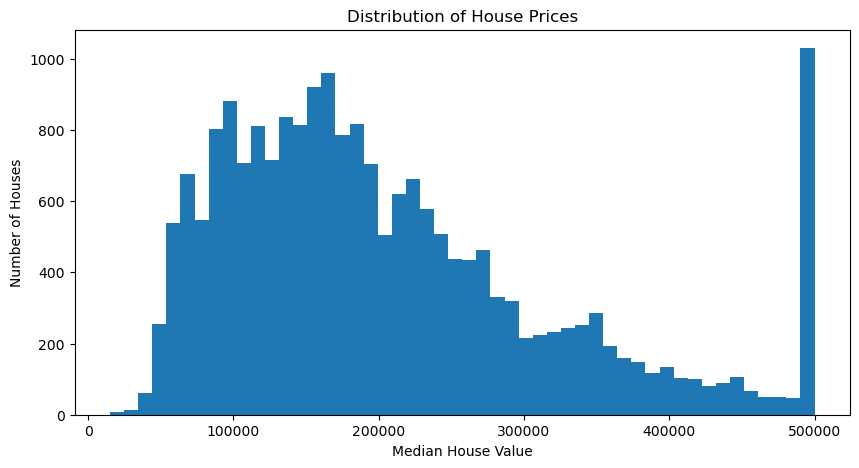

In [8]:
# Step 15: House Price Distribution

plt.figure(figsize=(10, 5))

plt.hist(df['median_house_value'], bins=50)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")

plt.show()

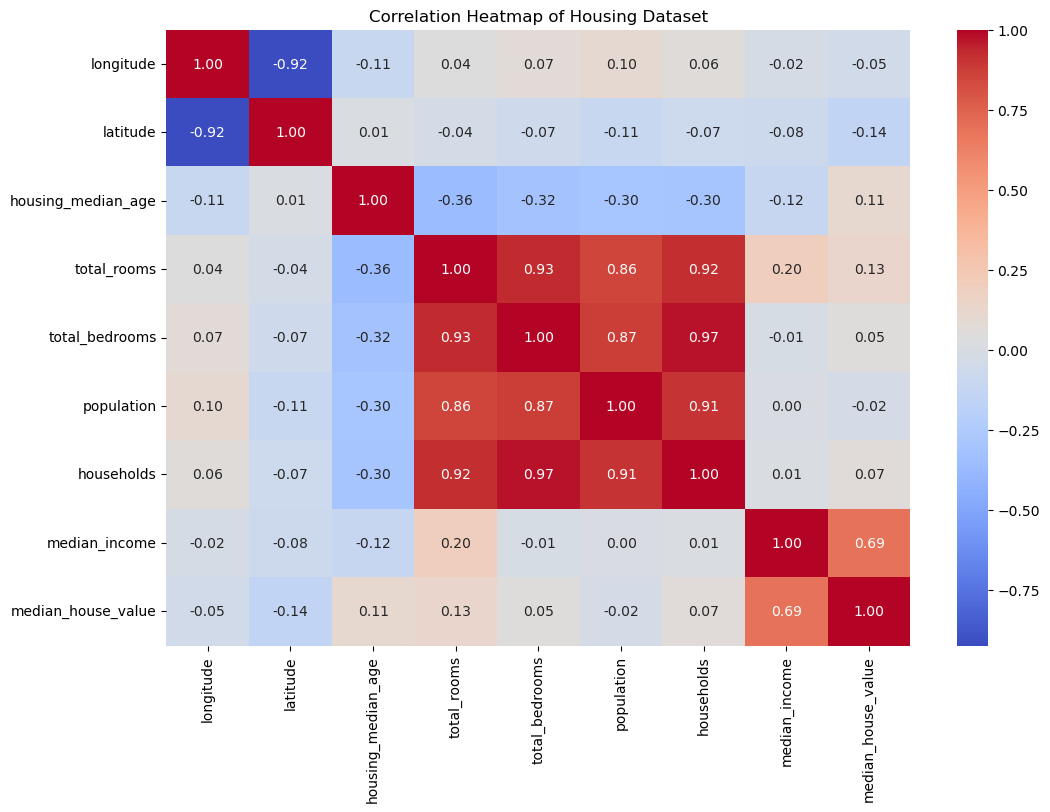

In [9]:
# Step 16: Correlation Analysis

correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Housing Dataset")

plt.show()

In [10]:
# Step 17: Separate Features and Target

# Input features
X = df.drop(
    ['median_house_value', 'ocean_proximity'],
    axis=1
)

# Target variable
y = df['median_house_value']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (20640, 8)
Target Variable Shape: (20640,)


In [11]:
# Step 18: Split Dataset into Training and Testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (16512, 8)
Testing Data Shape: (4128, 8)
Training Target Shape: (16512,)
Testing Target Shape: (4128,)


In [12]:
# Step 19: Create Linear Regression Model

# Create model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [13]:
# Step 20: Predict House Prices

y_pred = model.predict(X_test)

print("Actual House Prices:")
print(y_test.head(10).values)

print("\nPredicted House Prices:")
print(y_pred[:10])

Actual House Prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

Predicted House Prices:
[ 63736.59133838 154344.5943191  253073.19428744 263507.74653596
 266883.35961063 155403.49446604 287058.65420016 223660.78155238
 257045.02718266 404273.36611268]


In [14]:
# Step 21: Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance Results")

print("--------------------------")

print("Mean Absolute Error (MAE):", mae)

print("Mean Squared Error (MSE):", mse)

print("Root Mean Squared Error (RMSE):", rmse)

print("R2 Score:", r2)

Model Performance Results
--------------------------
Mean Absolute Error (MAE): 51810.483628042675
Mean Squared Error (MSE): 5059928371.165355
Root Mean Squared Error (RMSE): 71133.17349286024
R2 Score: 0.6138664756435177


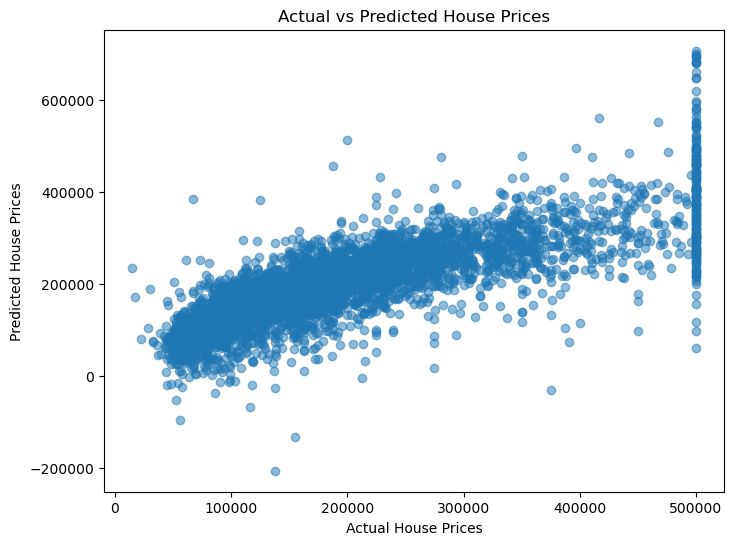

In [15]:
# Step 22: Actual vs Predicted House Prices

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

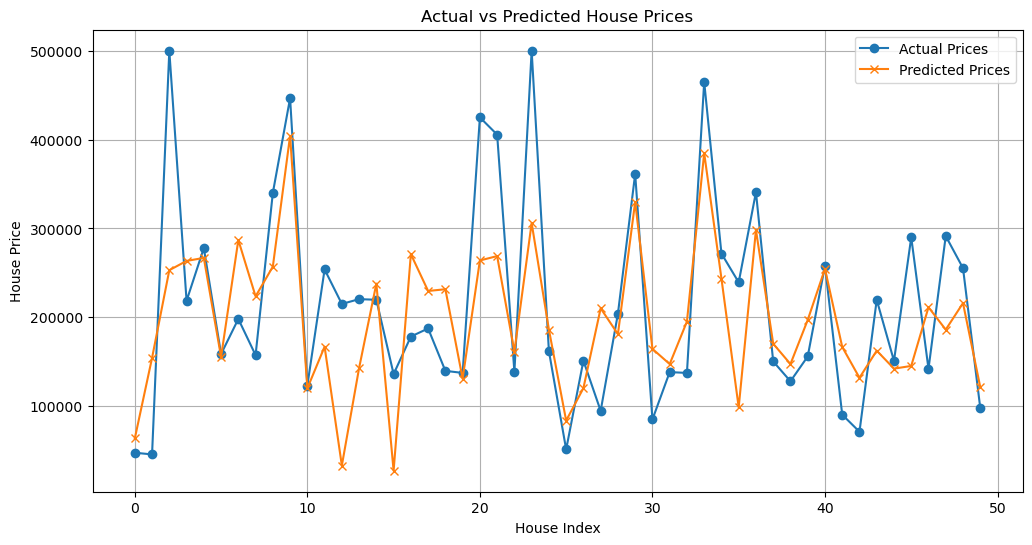

In [16]:
# Step 22: Compare Actual vs Predicted Prices

plt.figure(figsize=(12, 6))

plt.plot(y_test.values[:50], label="Actual Prices", marker='o')

plt.plot(y_pred[:50], label="Predicted Prices", marker='x')

plt.title("Actual vs Predicted House Prices")

plt.xlabel("House Index")

plt.ylabel("House Price")

plt.legend()

plt.grid(True)

plt.show()

In [17]:
# Step 23: Save the Trained Model

import pickle

# Save model
with open("../house_price_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [18]:
# Step 24: Load Saved Model

with open("../house_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [19]:
# Step 25: Evaluate Model Performance

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance:")
print("---------------------------")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Model Performance:
---------------------------
Mean Absolute Error: 51810.483628042675
Mean Squared Error: 5059928371.165355
Root Mean Squared Error: 71133.17349286024
R2 Score: 0.6138664756435177


In [20]:
# Step 26: Create Prediction Function

def predict_house_price(
    longitude,
    latitude,
    housing_median_age,
    total_rooms,
    total_bedrooms,
    population,
    households,
    median_income
):

    input_data = pd.DataFrame([[
        longitude,
        latitude,
        housing_median_age,
        total_rooms,
        total_bedrooms,
        population,
        households,
        median_income
    ]], columns=X.columns)

    prediction = loaded_model.predict(input_data)

    return prediction[0]


print("Prediction function created successfully!")

Prediction function created successfully!


In [21]:
# Step 27: Test House Price Prediction

predicted_price = predict_house_price(
    -122.23,
    37.88,
    41,
    880,
    129,
    322,
    126,
    8.3252
)

print("Predicted House Price:", predicted_price)

Predicted House Price: 411946.6103921775
